In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
path = 'Data/Space_Corrected.csv'
space_df = pd.read_csv(path)

In [4]:
space_df.columns #checking to see if ts actually works

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Company Name', 'Location', 'Datum',
       'Detail', 'Status Rocket', ' Rocket', 'Status Mission'],
      dtype='str')

In [7]:
space_df.head() #checking out how this is organized so i can figure out how to come up with a correlation visual

,Unnamed: 0.1,Unnamed: 0,Company Name,Location,Datum,Detail,Status Rocket,Rocket,Status Mission
0,0,0,SpaceX,"LC-39A, Kennedy Space Center, Florida, USA","Fri Aug 07, 2020 05:12 UTC",Falcon 9 Block 5 | Starlink V1 L9 & BlackSky,StatusActive,50.0,Success
1,1,1,CASC,"Site 9401 (SLS-2), Jiuquan Satellite Launch Ce...","Thu Aug 06, 2020 04:01 UTC",Long March 2D | Gaofen-9 04 & Q-SAT,StatusActive,29.75,Success
2,2,2,SpaceX,"Pad A, Boca Chica, Texas, USA","Tue Aug 04, 2020 23:57 UTC",Starship Prototype | 150 Meter Hop,StatusActive,NaN,Success
3,3,3,Roscosmos,"Site 200/39, Baikonur Cosmodrome, Kazakhstan","Thu Jul 30, 2020 21:25 UTC",Proton-M/Briz-M | Ekspress-80 & Ekspress-103,StatusActive,65.0,Success
4,4,4,ULA,"SLC-41, Cape Canaveral AFS, Florida, USA","Thu Jul 30, 2020 11:50 UTC",Atlas V 541 | Perseverance,StatusActive,145.0,Success


In [22]:
#ok so now that I have an idea as to what this dataset actually is, I wanna compare and contrast the success/failure against each company


companies_unique = space_df["Company Name"].unique() #lets start by first finding each of the unique company names
for company in companies_unique:
    print(company)

SpaceX
CASC
Roscosmos
ULA
JAXA
Northrop
ExPace
IAI
Rocket Lab
Virgin Orbit
VKS RF
MHI
IRGC
Arianespace
ISA
Blue Origin
ISRO
Exos
ILS
i-Space
OneSpace
Landspace
Eurockot
Land Launch
CASIC
KCST
Sandia
Kosmotras
Khrunichev
Sea Launch
KARI
ESA
NASA
Boeing
ISAS
SRC
MITT
Lockheed
AEB
Starsem
RVSN USSR
EER
General Dynamics
Martin Marietta
Yuzhmash
Douglas
ASI
US Air Force
CNES
CECLES
RAE
UT
OKB-586
AMBA
Arm??e de l'Air
US Navy


In [35]:
#ok that worked so now I want to tally up the success and failures for these companies

successes = [] #start by creating an empty list container for both successs and failures
failures = []

#start with creating a for loop that goes through the status and counts successes by the string and if it does match success its a failure
for company in companies_unique:
    company_name = space_df[space_df["Company Name"] == company]
    success_count = (company_name["Status Mission"] == "Success").sum()
    failure_count = (company_name["Status Mission"] != "Success").sum()

    #takes the tallies and applies it to the empty list container
    successes.append(success_count)
    failures.append(failure_count)

#map out the results side by side
company_results = pd.DataFrame({"Company": companies_unique, "Success": successes, "Failure": failures})
print(company_results)

             Company  Success  Failure
0             SpaceX       94        6
1               CASC      231       20
2          Roscosmos       51        4
3                ULA      139        1
4               JAXA        6        1
5           Northrop       74        9
6             ExPace        9        1
7                IAI        9        2
8         Rocket Lab       11        2
9       Virgin Orbit        0        1
10            VKS RF      188       13
11               MHI       80        4
12              IRGC        1        0
13       Arianespace      269       10
14               ISA        4        9
15       Blue Origin       12        0
16              ISRO       63       13
17              Exos        0        4
18               ILS       45        1
19           i-Space        1        0
20          OneSpace        0        1
21         Landspace        0        1
22          Eurockot       12        1
23       Land Launch        6        1
24             CASIC     

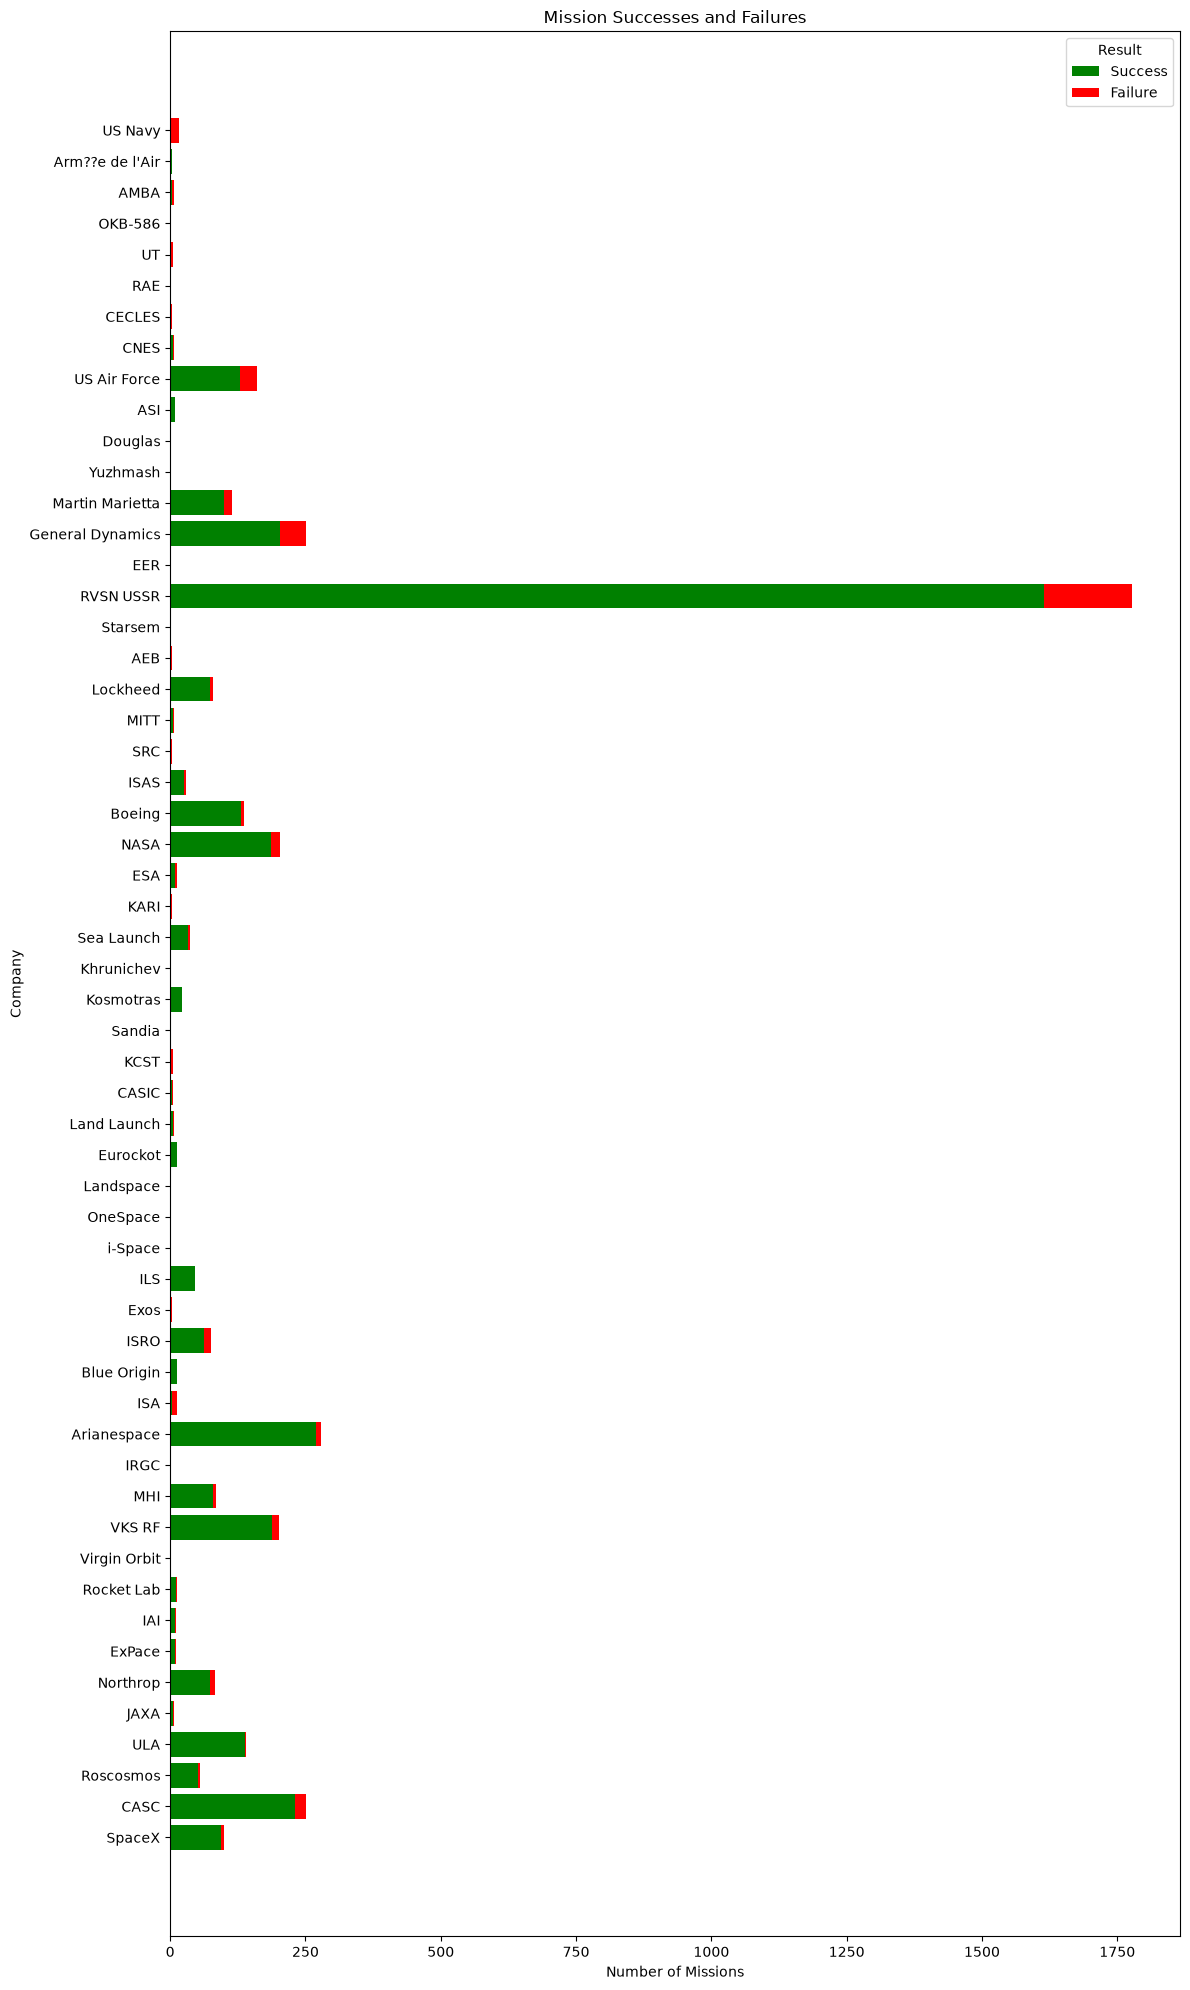

In [40]:
#finally I want to list this visually in a horizontal histogram using barh
plt.figure(figsize=(12, 20))

plt.barh(company_results["Company"], company_results["Success"],color="green",label="Success")

plt.barh(company_results["Company"],company_results["Failure"],left=company_results["Success"],color="red",label="Failure")

plt.title("Mission Successes and Failures")
plt.xlabel("Number of Missions")
plt.ylabel("Company")
plt.legend(title="Result")
plt.tight_layout()
plt.show()